# Committor from an infretis StapleTIS Run (1D)

Fits the committor with NPNEq (`CommittorNE`, CuPy) to the paths of an **infretis StapleTIS** simulation and compares it with the exact committor.

**How the paths become training data** (the same code as `load_tis_data_cupy.py`: `tis_data.prepare_data`, which switches to `infretis_data.py` for infretis runs; details in `docs/npneq_tis_notes.md`, sections 3, 9 and 15):
- **Read with infretis' own definitions:** interfaces and swap settings from `infretis.toml`, one row per finished path from `infretis_data.txt`, the order parameters from `load/<pnr>/order.txt` (or an h5 archive), and each path's core in an ensemble from infretis' `StaplePath.get_sh_region`.
- **Cut at M:** an ensemble only keeps paths that cross its middle interface M, so the frames before that crossing are conditioned on their future. Every (path, ensemble) pair gives one piece: the path from its first frame past M (searched from the core start) to its end. Optionally also the *mirrored piece*: the part before the last M crossing, read backwards (`REVERSED`).
- **Weights:** infretis records per (path, ensemble) the occupancy `path_f` and the weight `path_w` it put into the swap matrix (0.5 for LML/RMR paths in the inner staple ensembles). The weighting has to undo how the sampler used w: with swaps (infinite swap or staple swaps) that is `path_f / path_w` (`'staple'`), with shooting only `path_f` (`'rejections'`). By default the loader picks this from the run (`WEIGHTINGS = [None]`); several weightings can be fitted side by side by listing them.

**Default run:** `staple_flat_walls_br` (infretis ASE example): one particle on a flat potential with harmonic walls at x = −0.2 and 0.4, overdamped Langevin; interfaces −0.1, 0.0, 0.1, 0.2, 0.3; infinite swap; 41648 paths. A: λ ≤ −0.1, B: λ ≥ 0.3.

**Exact committor:** the committor of the discrete chain the engine runs (section 5): x' = x + μ F(x) + σ ξ with μ = dt/(mγ), σ² = 2 kT μ, A and B checked every step, solved on a grid with exact error-function integration (`exact_tools.solve_brownian_1d`) and Richardson-extrapolated in the grid spacing. The force F comes from the engine's calculator in `infretis.toml` (flat walls, or the cosine bump of `1cosbump`); for another potential give `FORCE_1D`. Do not use the linear committor of a flat potential for a run with a barrier: for the 1 kT bump of `1cosbump` it is off by up to 0.08.

## 1. Imports

In [1]:
import argparse
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cupy as cp

plt.rc('font', size=10)
plt.rc('axes', titlesize=12)
plt.rc('axes', labelsize=12)
plt.rc('legend', fontsize=9)

# Run from examples/: the CuPy optimalrcs package and the path readers of the examples
REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs
import tis_data
import infretis_data
import seed_runs
FIG = f'{REPO}/examples/figures_by_potential'

## 2. Settings

**Run and data**

| Name | Meaning |
|---|---|
| `TIS_DIR` | the infretis simulation folder (`infretis.toml`, `infretis_data.txt`, `load/`) |
| `H5_FILE` | order parameters from an `inft store_txt -order` archive instead of `load/` (`None`: use `load/`) |
| `LAMBDA_A`, `LAMBDA_B` | states A (λ ≤ λ_A) and B (λ ≥ λ_B); `None`: the first and last interface |
| `BURN_IN_FRACTION` | the first part of the rows of `infretis_data.txt` (the order in which the paths ended) is skipped; the initial load paths always are |
| `PATHS_PER_ENSEMBLE`, `THIN` | at most this many paths per ensemble, evenly spaced (`None`: all), after keeping every `THIN`-th |
| `REVERSED` | also use the mirrored pieces (time-reversible dynamics at equilibrium) |
| `WEIGHTINGS` | the weightings to fit, one fit each: `None` = the run's default, `'staple'` = path_f / path_w, `'rejections'` = path_f, `'none'` = 1 per (path, ensemble). One entry is enough; list several to compare them |

**Fit** (the same for every weighting): `SEEDS` (which CV and envelope centre each iteration draws), a warm-up of `WARMUP_ITER` iterations with a wide envelope, then `MAX_ITER` iterations, in chunks of `CHUNK` after which the plots are shown and saved. `STOPPED_ENDS` (default `True`): a piece that ends outside A and B was stopped by the path's own end (a turn); the stopped Z_q then uses q at that end for windows that pass it (`set_stopped_traj_end`), and the A/B traps are made long enough that no window is dropped. `NY` is the degree of the polynomial basis, `LAZY_BASIS` evaluates it on the fly (GPU memory).

In [66]:
TIS_DIR = f'{REPO}/examples/data/infretis_inputs/flat1d_br'
H5_FILE = f'{REPO}/examples/data/infretis_inputs/flat1d_br/paths_correctw.h5'
LAMBDA_A, LAMBDA_B = -0.1, 0.3    # None: first and last interface
BURN_IN_FRACTION = 0.2
PATHS_PER_ENSEMBLE = 5000          # None: all paths after the burn-in
THIN = 1
REVERSED = True
WEIGHTINGS = ['rejections']                # e.g. [None], ['staple', 'rejections']
FORCE_1D = None                  # force F(x) of the engine for the exact committor (section 5): None = from the calculator in infretis.toml (flat or cosine bump), or a function x -> F in engine units

SEEDS = [111]
WARMUP_ITER, WARMUP_ENVELOPE = 1000, 1
MAX_ITER, CHUNK = 4000, 1000
ENVELOPE, GAMMA = 0.01, 0.1
STOPPED_ENDS = True                # stopped Z_q: a window passing a turn end of a piece uses q at that end
NY, LAZY_BASIS = 6, True           # basis degree; evaluate the basis on the fly (GPU memory)
PLOTS = ('metrics', 'tis',  'feps', 'obs_pred')         # library plots after every chunk; also possible: 'obs_pred_log'
LABEL = 'order parameter $\\lambda$'
N_BINS = 80                        # bins along lambda for the profiles

RUN_NAME = os.path.basename(TIS_DIR.rstrip('/'))
OUT = f'{FIG}/1d_flat/infretis_staple/{RUN_NAME}'
print('figures and results in', OUT)

figures and results in /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_flat/infretis_staple/flat1d_br


## 3. The Run

What infretis wrote: the sampling settings, and per ensemble its window (L, M, R), the number of finished paths with a nonzero occupancy, their total occupancy `path_f`, and the share of that occupancy with `path_w` ≠ 1 (where `'staple'` and `'rejections'` differ).

**Weight check** (`infretis_data.weight_consistency`, needs no committor). A path that is valid in two ensembles e and e′ should split its occupancy in the same ratio C_e / C_e′ whatever its type. So the ratio Σ weight_e / Σ weight_e′ over paths of one class (w_e, w_e′) must not depend on the class: relative to class (1, 1), the classes (0.5, 1) and (1, 0.5) should give 1 for the right weighting. Runs with swaps show which one that is. Runs with shooting only have no paths shared between ensembles, and the check is empty.

In [67]:
settings = infretis_data.read_settings(TIS_DIR)
table = infretis_data.read_infretis_data(os.path.join(TIS_DIR, 'infretis_data.txt'), len(settings['interfaces']))
default_w, why = infretis_data.default_weighting(settings)
print(f"mode {settings['mode']}, infinite swap {settings['infinite_swap']}, staple swap fraction "
      f"{settings['staple_swap_frac']}, {len(table['pnr'])} finished paths")
print(f"interfaces {settings['interfaces']}")
print(f"default weighting: {default_w} ({why})")

f, w = table['path_f'], table['path_w']
rows = []
for e in range(len(settings['interfaces'])):
    on = f[:, e] > 0
    rows.append(dict(ensemble=f'{e:03d}', window=tuple(round(v, 4) for v in infretis_data.ensemble_window(settings, e)),
                     paths=int(on.sum()), occupancy=f[on, e].sum(),
                     share_w_not_1=(f[on, e] * ~np.isclose(w[on, e], 1)).sum() / max(f[on, e].sum(), 1e-12)))
display(pd.DataFrame(rows).set_index('ensemble').round(3))

check = infretis_data.weight_consistency(table)
w_not_1 = ((f > 0) & ~np.isclose(w, 1)).any()
if not w_not_1:
    print("path_w is 1 for every occupied (path, ensemble) pair (no wire fencing, no staple weights): 'staple' (path_f / path_w) "
          "and 'rejections' (path_f) are the same weights for this run, and the weight check below has nothing to compare")
if not check:
    print('weight check: no class of paths with w != 1 that is shared by two ensembles' if not w_not_1 else
          'weight check: no pairs of ensembles with enough shared paths (expected for shooting only)')
else:
    out = []
    for row in check:
        for c in ((0.5, 1), (1, 0.5)):
            if c in row:
                out.append(dict(pair=row['pair'], cls=c, n=row['n'][c],
                                path_f=f"{row[c]['rejections'][0]:.3f} ± {row[c]['rejections'][1]:.3f}",
                                path_f_over_w=f"{row[c]['staple'][0]:.3f} ± {row[c]['staple'][1]:.3f}"))
    display(pd.DataFrame(out))

mode staple, infinite swap True, staple swap fraction 0.5, 34137 finished paths
interfaces [-0.1, 0.0, 0.1, 0.2, 0.3]
default weighting: staple (StapleTIS with infinite swap: the permanent of W splits the occupancies by w)


,window,paths,occupancy,share_w_not_1
ensemble,,,,
000,"(-inf, -0.1, -0.1)",9032,29485.0,0.000
001,"(-0.1, -0.1, 0.0)",10437,30121.5,0.000
002,"(-0.1, 0.0, 0.1)",9424,26819.0,0.241
003,"(0.0, 0.1, 0.2)",10614,25883.5,0.464
004,"(0.1, 0.2, 0.3)",8939,26827.0,0.242


,pair,cls,n,path_f,path_f_over_w
0,"(2, 3)","(0.5, 1)",1354,0.500 ± 0.028,1.001 ± 0.055
1,"(2, 3)","(1, 0.5)",1024,2.051 ± 0.096,1.025 ± 0.048
2,"(2, 4)","(0.5, 1)",680,0.499 ± 0.042,0.999 ± 0.085
3,"(2, 4)","(1, 0.5)",621,1.895 ± 0.339,0.948 ± 0.169
4,"(3, 4)","(0.5, 1)",1059,0.542 ± 0.020,1.084 ± 0.041
5,"(3, 4)","(1, 0.5)",1315,2.044 ± 0.143,1.022 ± 0.072


## 4. From Paths to Frames

`tis_data.prepare_data` reads the run once per weighting in `WEIGHTINGS` (the pieces are the same, only their weights differ). It returns per frame: the CVs, λ, the time within its path (`t_traj`), its piece (`i_traj`), its path (`group_traj`, the infretis path number), the path weight (`path_weights`, mean 1) and the A/B masks.

The plots show where the frames are: the weighted number of frames along λ (the path-sampling density, high at the interfaces where pieces start, not the equilibrium distribution), and the piece lengths.

State A: order <= -0.1, state B: order >= 0.3
infretis run /local/data/data-fbsskr/Students/elias/optimalrcs/examples/data/infretis_inputs/flat1d_br: mode staple, infinite swap True, 5 ensembles, 34137 finished paths in /local/data/data-fbsskr/Students/elias/optimalrcs/examples/data/infretis_inputs/flat1d_br/infretis_data.txt
Interfaces: [-0.1, 0.0, 0.1, 0.2, 0.3]
  path_w != 1 for 10986 (path, ensemble) pairs, 17.9% of the occupancy; path_f and path_f / path_w differ there by a factor [2.]
  Note (StapleTIS): path_f / path_w is the natural measure of the stored staple paths (crossing probabilities, rates). For committor pieces use path_f (--weights rejections): an LML/RMR core is stored twice, once with each turn (the extension's coin flip, w = 1/2 each), and path_f counts the core once; see docs/op_loop_report.md.
Order parameters from /local/data/data-fbsskr/Students/elias/optimalrcs/examples/data/infretis_inputs/flat1d_br/paths_correctw.h5: 14909 paths read
  ensemble 001: 5000 pat

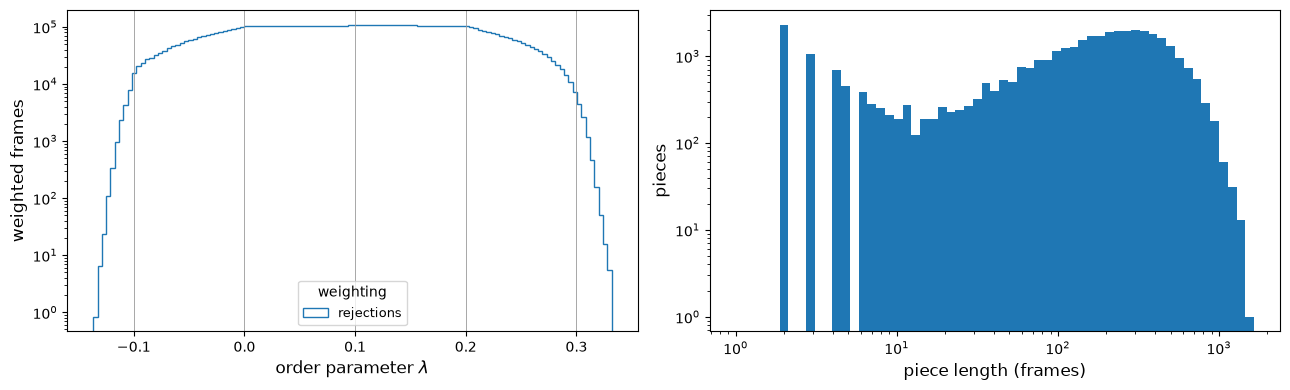

In [68]:
def prepare(weighting):
    parser = argparse.ArgumentParser()
    tis_data.add_data_arguments(parser)
    argv = [TIS_DIR, '--burn-in-fraction', str(BURN_IN_FRACTION), '--thin', str(THIN)]
    if weighting is not None:
        argv += ['--weights', weighting]
    if H5_FILE is not None:
        argv += ['--h5', H5_FILE]
    if LAMBDA_A is not None:
        argv += ['--lambda-a', str(LAMBDA_A)]
    if LAMBDA_B is not None:
        argv += ['--lambda-b', str(LAMBDA_B)]
    if PATHS_PER_ENSEMBLE is not None:
        argv += ['--paths-per-ensemble', str(PATHS_PER_ENSEMBLE)]
    if REVERSED:
        argv += ['--reversed']
    args = parser.parse_args(argv)
    data = tis_data.prepare_data(args)
    return args.weights, args.lambda_a, args.lambda_b, data     # the weighting actually used


# None = the run's default (section 3); the same weighting twice is fitted once
names = list(dict.fromkeys(w if w is not None else default_w for w in WEIGHTINGS))
datas = {}
for weighting in names:
    name, lambda_a, lambda_b, data = prepare(weighting)
    datas[name] = data
    print(f'--> {name}: {len(data.lam)} frames, {data.i_traj.max() + 1} pieces, '
          f'{len(np.unique(data.group_traj))} paths\n')
data = next(iter(datas.values()))  # the frames are the same for every weighting
free = ~(data.boundary0 | data.boundary1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
e_lam = np.linspace(data.lam.min(), data.lam.max(), 121)
for name, d in datas.items():
    ax1.hist(d.lam, bins=e_lam, weights=d.path_weights, histtype='step', label=name)
for v in settings['interfaces']:
    ax1.axvline(v, color='0.6', lw=0.6)
ax1.set(xlabel=LABEL, ylabel='weighted frames', yscale='log')
ax1.legend(title='weighting')
lengths = np.bincount(data.i_traj)
ax2.hist(lengths, bins=np.logspace(0, np.log10(lengths.max() + 1), 60))
ax2.set(xscale='log', yscale='log', xlabel='piece length (frames)', ylabel='pieces')
fig.tight_layout()
plt.show()

## 5. Exact Committor

The committor of the discrete chain the engine runs, not of the continuous dynamics: overdamped ASE steps x' = x + μ F(x) + σ ξ with μ = dt/(mγ), σ² = 2 kT μ (from `[engine]` in `infretis.toml`: `timestep` in fs, `langevin_friction` per fs, `temperature` in K, converted with `ase.units`), absorption in A (λ ≤ λ_A) and B (λ ≥ λ_B) checked every step. q(x) = P(x' ≥ B) + ∫ N(x'; x + μF(x), σ) q(x') dx' is solved on a grid with q piecewise linear and the Gaussian integrated against it exactly (`exact_tools.solve_brownian_1d`); the grid is refined to h = σ/20 and σ/40 and the two are Richardson-extrapolated (the error estimate is printed).

The force F(x) is read from the calculator in `infretis.toml`: `FlatWalls1D` (zero between A and B) or `CosBumpSeriesWalls1D` (`deltaf/2 (1 − cos(2π (x − bleft)/L))` bumps). For another potential set `FORCE_1D` (a function x → F in engine units). Without ASE constants (another engine) the step size σ is measured from the data and only a force-free potential can be done. Or set `q_exact_of = None` to skip the reference.

**Do not use the flat-potential formula for a run with a barrier.** The committor of a flat potential is linear (between the boundaries moved out by the mean overshoot s = 0.5826 σ of one step); with the 1 kT bump of `1cosbump` the true committor is steepest at the top and differs from it by up to 0.08 (RMS 0.056), which is most of what an earlier version of this notebook reported as the fit error.

In [69]:
import tomllib
sys.path.insert(0, f'{FIG}/_shared/exact_committors')
import exact_tools as E

with open(f'{TIS_DIR}/infretis.toml', 'rb') as fh:
    cfg = tomllib.load(fh)
eng = cfg['engine']
calc = eng.get('calculator_settings', {})

# step size of lambda between A and B, measured from the data (a check of the chain constants below)
same = data.i_traj[1:] == data.i_traj[:-1]
inside = same & (data.lam[:-1] > lambda_a + 0.02) & (data.lam[:-1] < lambda_b - 0.02)
step = np.diff(data.lam)[inside]
sigma_data = step.std()
print(f'step size from the data: sigma = {sigma_data:.5f} (mean step {step.mean():+.1e}, {inside.sum()} steps)')

# the chain: dt, gamma, kT, mass
if eng.get('engine') == 'ase' and 'overdamped' in eng.get('integrator', '').lower():
    from ase import units
    mass = eng['particles']['mass'][0]
    dt, gamma, kT = eng['timestep'] * units.fs, eng['langevin_friction'] / units.fs, units.kB * eng['temperature']
    constants_known = True
    sigma_chain = np.sqrt(2 * kT * dt / (mass * gamma))
    print(f'chain from infretis.toml: mu = dt/(m gamma) = {dt / (mass * gamma):.3e}, sigma = {sigma_chain:.5f}, kT = {kT:.4f}'
          f'  (data: {sigma_data:.5f})')
else:
    mass, gamma, dt, kT = 1.0, 1.0, 1.0, sigma_data ** 2 / 2          # only sigma matters for zero force
    constants_known = False
    sigma_chain = sigma_data
    print('engine constants unknown: using the measured sigma, force-free potentials only')

# the force F(x)
if FORCE_1D is not None:
    force_1d = FORCE_1D
elif calc.get('class') == 'CosBumpSeriesWalls1D':
    bl, br, deltaf, nbump = calc['bleft'], calc['bright'], calc['deltaf'], calc.get('nbump', 1)
    width = br - bl
    force_1d = lambda x: np.where((x >= bl) & (x <= bl + nbump * width),
                                  -deltaf * np.pi / width * np.sin(2 * np.pi * (x - bl) / width), 0.0)
    print(f'force: {nbump} cosine bump(s) of height {deltaf} (energy units) on [{bl}, {bl + nbump * width}]')
elif 'Flat' in calc.get('class', ''):
    if not (calc.get('left', -np.inf) <= lambda_a and calc.get('right', np.inf) >= lambda_b):
        print('warning: the walls of the flat potential are inside [lambda_A, lambda_B]; the reference ignores them')
    force_1d = lambda x: np.zeros_like(x)
    print('force: flat potential between A and B')
else:
    raise ValueError(f"unknown calculator {calc.get('class')!r}: set FORCE_1D (a function x -> F) or q_exact_of = None")
if not constants_known and FORCE_1D is not None:
    raise ValueError('a user force needs the engine constants (dt, gamma, kT, mass): an ASE overdamped run, or set q_exact_of yourself')

# solve on two grids (h = sigma/20, sigma/40) and extrapolate (the error is O(h^2))
ns = [min(int(round((lambda_b - lambda_a) / (sigma_chain / k))) + 1, 6000) for k in (20, 40)]
sols = [E.solve_brownian_1d(force_1d, dt, gamma, kT, lambda_a, lambda_b, n, m=mass) for n in ns]
grid = np.linspace(lambda_a, lambda_b, 4001)
q_a, q_b = (np.interp(grid, *s) for s in sols)
q_grid = q_b + (q_b - q_a) / 3
print(f'exact committor: grids of {ns[0]} and {ns[1]} nodes differ by at most {np.abs(q_b - q_a).max():.1e} '
      f'(Richardson error estimate {np.abs(q_b - q_a).max() / 3:.1e})')
shift = 0.5826 * sigma_chain
q_flat = np.clip((grid - lambda_a + shift) / (lambda_b - lambda_a + 2 * shift), 0, 1)
print(f'for comparison, the flat-potential (linear) committor differs from it by up to {np.abs(q_flat - q_grid).max():.4f} '
      f'(RMS {np.sqrt(np.mean((q_flat - q_grid) ** 2)):.4f})')


def q_exact_of(X):
    return np.interp(X[:, 0], grid, q_grid)


step size from the data: sigma = 0.00894 (mean step +1.2e-06, 8038106 steps)
chain from infretis.toml: mu = dt/(m gamma) = 4.000e-05, sigma = 0.00894, kT = 1.0000  (data: 0.00894)
force: flat potential between A and B
exact committor: grids of 895 and 1790 nodes differ by at most 3.4e-06 (Richardson error estimate 1.1e-06)
for comparison, the flat-potential (linear) committor differs from it by up to 0.0027 (RMS 0.0003)


## 6. Fit the Committor

One fit per weighting (and per seed in `SEEDS`), on the same frames. `CommittorNE` with `group_traj` (the pieces of one path count as one unit in the error estimates), the **A/B ends as traps** (`set_fixed_traj_length_trap`: longer than any piece plus the longest Z_q lag, so no window is dropped), and the **stopped ends** (`set_stopped_traj_end`, `STOPPED_ENDS`): a piece that ends outside A and B was stopped by the path's own end (a turn), so a window that passes it uses q at that end instead of being dropped, which would condition on the path not stopping earlier.

The first cell defines the plots, the progress line and the piece ends; the second builds the committor, runs `fit_transform` for the warm-up (wide envelope) and then in chunks of `CHUNK` iterations (it continues from the current q), and `seed_runs.save_and_show` shows and saves after the warm-up and every chunk as `<OUT>/<weighting>/seed<s>/it<N>_<plot>.png`:
- `metrics`: `dr2`, `zqs_z` and `|dx|` over the iterations. **Convergence: `zqs_z`** (the worst |stopped Z_q / standard error| over q and lags) about 2 or less, with `|dx|` small. For pieces cut at M the stopped Z_q of the committor is 0 at every q and lag (notes §5, §8.1);
- `tis`: the stopped Z_q per lag, the short-lag Z_q and the stopped observed-vs-predicted;
- `feps`, `obs_pred` (if listed in `PLOTS`): the library's original plots, biased for path pieces; with `STOPPED_ENDS` the Z_q of `feps` is the stopped one;
- `q_profile`: the path-weighted mean q per λ bin next to the exact committor, and fit − exact;

The progress line gives the path-weighted RMS(fit − exact) over the frames with 0.05 < q_exact < 0.95. Each weighting's final q per frame is kept in `fits` for section 7.

In [70]:
def edges_for(d):
    return (np.linspace(lambda_a, lambda_b, N_BINS + 1),)


def extras_for(d, qe):
    # q -> figure: the path-weighted mean q per lambda bin, against the exact committor
    edges = edges_for(d)
    fr = ~(d.boundary0 | d.boundary1)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    mid = (edges[0][1:] + edges[0][:-1]) / 2
    prof_ex = None if qe is None else bm(d.path_weights * qe) / w_mean

    def q_profile(q):
        P = bm(d.path_weights * cp.asnumpy(q.r_traj)) / w_mean
        fig, axes = plt.subplots(1, 1 if qe is None else 2, figsize=(6 if qe is None else 13, 4), squeeze=False)
        axes[0, 0].plot(mid, P, label='fit')
        if qe is not None:
            axes[0, 0].plot(mid, prof_ex, 'k--', label='exact')
            t = (prof_ex > 0.05) & (prof_ex < 0.95)
            axes[0, 1].plot(mid, P - prof_ex)
            axes[0, 1].axhline(0, color='k', lw=0.8)
            axes[0, 1].set(xlabel=XLABEL, ylabel='fit $-$ exact',
                           title=f'RMS per bin (0.05 < exact < 0.95) {np.sqrt(np.nanmean((P - prof_ex)[t] ** 2)):.4f}')
            axes[0, 1].grid(alpha=0.3)
        axes[0, 0].set(xlabel=XLABEL, ylabel='$q$ (mean per bin)')
        axes[0, 0].legend()
        axes[0, 0].grid(alpha=0.3)
        fig.tight_layout()
        return fig

    extras = {'q_profile': q_profile}
    return extras


def report_for(d, qe):
    # progress line: path-weighted RMS(fit - exact) over the frames with 0.05 < q_exact < 0.95
    if qe is None:
        return None
    trans = ~(d.boundary0 | d.boundary1) & (qe > 0.05) & (qe < 0.95)
    idx, qe_g, w_g = (cp.asarray(a) for a in (np.flatnonzero(trans), qe[trans], d.path_weights[trans]))

    def report(q):
        diff = q.r_traj[idx] - qe_g
        return f'| RMS(fit - exact) {float(cp.sqrt(cp.sum(w_g * diff * diff) / cp.sum(w_g))):.4f}'
    return report


XLABEL = LABEL

# ---- piece ends: in A or B (trap), or stopped by the path's own end, a turn (stopped end)
# (the frames are the same for every weighting, so this is done once)
b_all = data.boundary0 | data.boundary1
piece_end = np.r_[np.flatnonzero(np.diff(data.i_traj)), len(data.i_traj) - 1]      # last frame of every piece
stop_end = np.zeros(len(b_all), bool)
stop_end[piece_end] = ~b_all[piece_end]
longest = int(np.bincount(data.i_traj - data.i_traj.min()).max())
TRAP_LEN = max(2 ** 16, longest + 2 ** 15 + 1)         # A/B trap: longer than any piece plus the longest Z_q lag (2^15)
print(f'{len(piece_end)} pieces: {stop_end.sum()} end at a turn (stopped), {len(piece_end) - stop_end.sum()} in A or B; '
      f'longest piece {longest} frames, A/B trap {TRAP_LEN}')

PRINT_STEP = min(500, CHUNK, WARMUP_ITER or CHUNK)    # the metrics are recorded every PRINT_STEP iterations (a plot needs a record)
METRICS = ['delta_r2', 'max_z_zq_stopped', 'delta_x']


def show_stage(q, folder, n_done, stage, extras, report):
    """Save and show the plots after a stage (<folder>/it<N>_<plot>.png), and print the progress."""
    seed_runs.save_and_show(q, folder, f'it{n_done}', PLOTS, dict(metrics=METRICS), extras)
    print(f'{n_done} iterations ({stage}) {"" if report is None else report(q)}', flush=True)


38956 pieces: 14516 end at a turn (stopped), 24440 in A or B; longest piece 1650 frames, A/B trap 65536


===== fit, weighting rejections, seed 111 =====
#=500, dr2=3918.83, zqs_z=2.65638, sdzqs=45.3206, |dx|=0.225667, time=34.8448
#=1000, dr2=3918.82, zqs_z=2.6564, sdzqs=45.3221, |dx|=1.24958e-06, time=67.7785
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_flat/infretis_staple/flat1d_br/rejections/seed111/it1000 ---


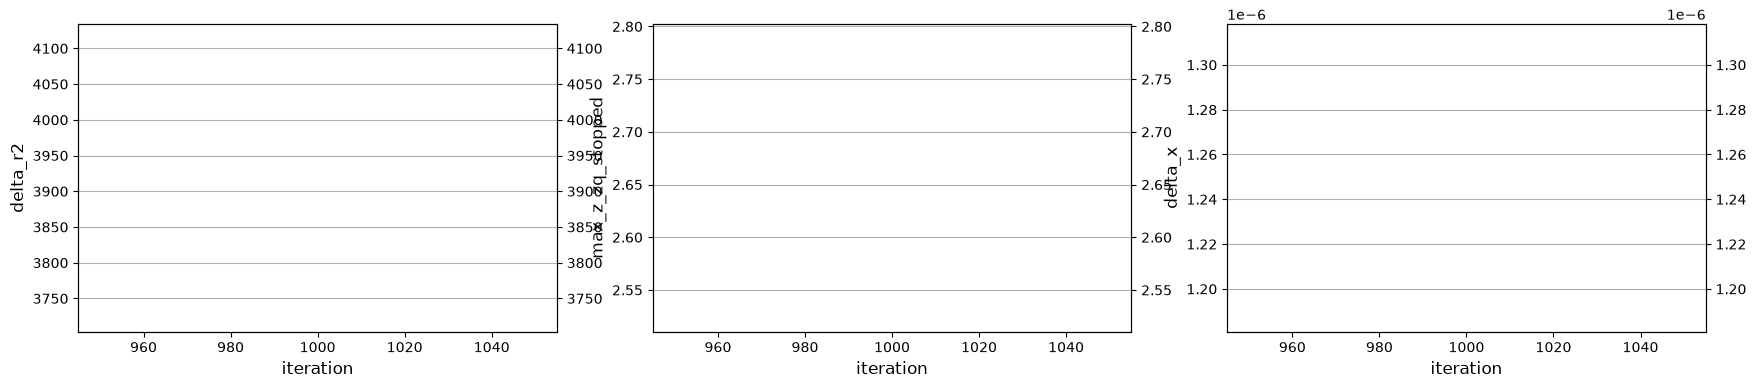

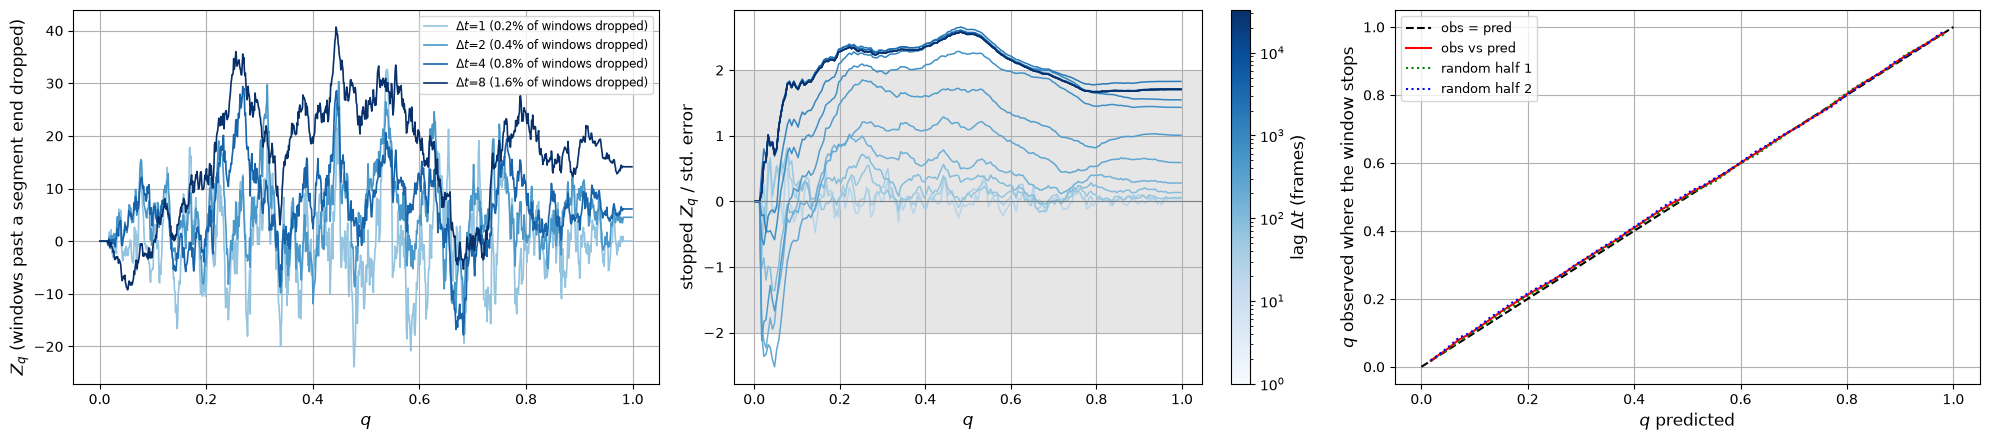

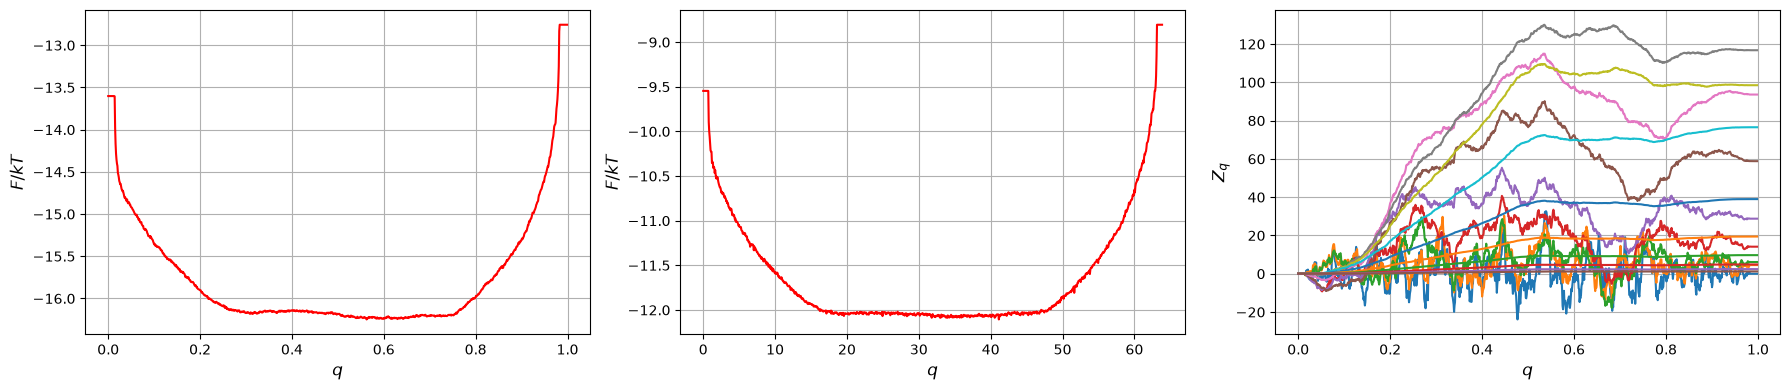

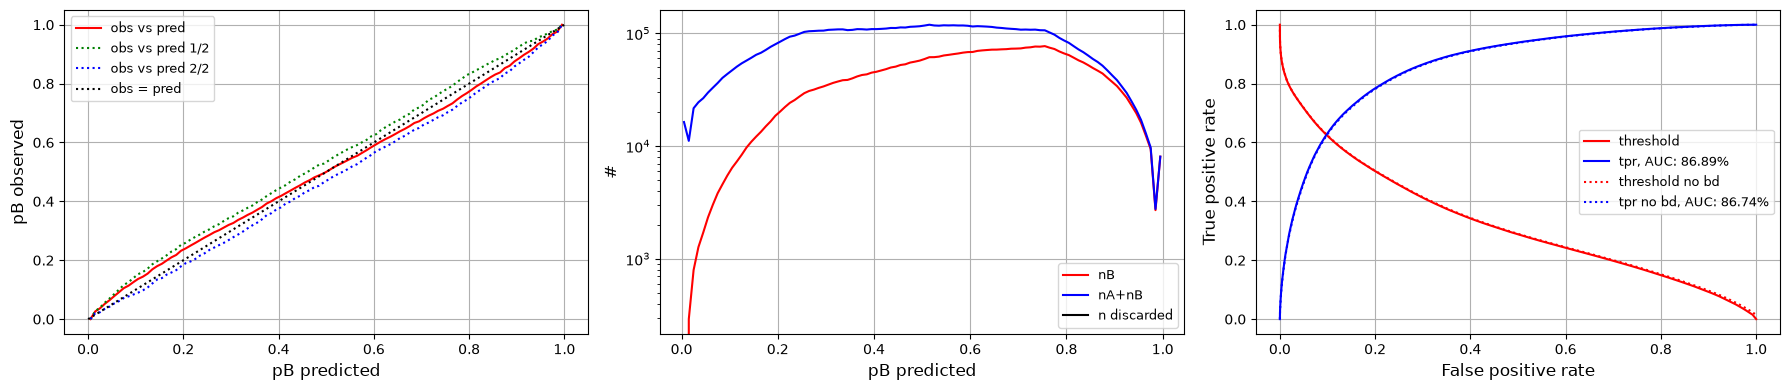

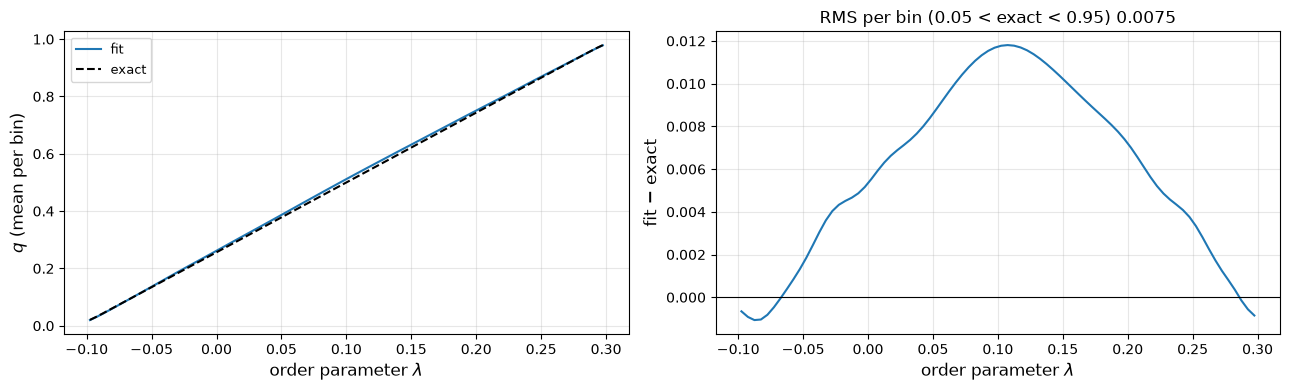

1000 iterations (warm-up, envelope 1) | RMS(fit - exact) 0.0082
#=1500, dr2=3918.72, zqs_z=2.67097, sdzqs=45.7852, |dx|=0.00010321, time=42.6528
#=2000, dr2=3918.65, zqs_z=2.66881, sdzqs=45.6816, |dx|=2.82387e-05, time=73.2817
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_flat/infretis_staple/flat1d_br/rejections/seed111/it2000 ---


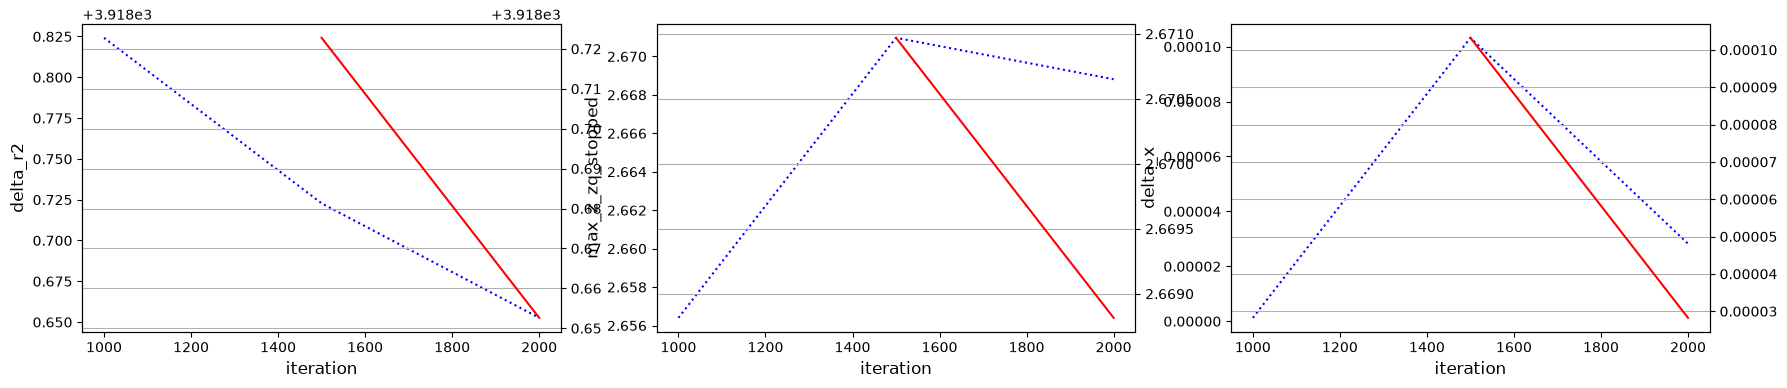

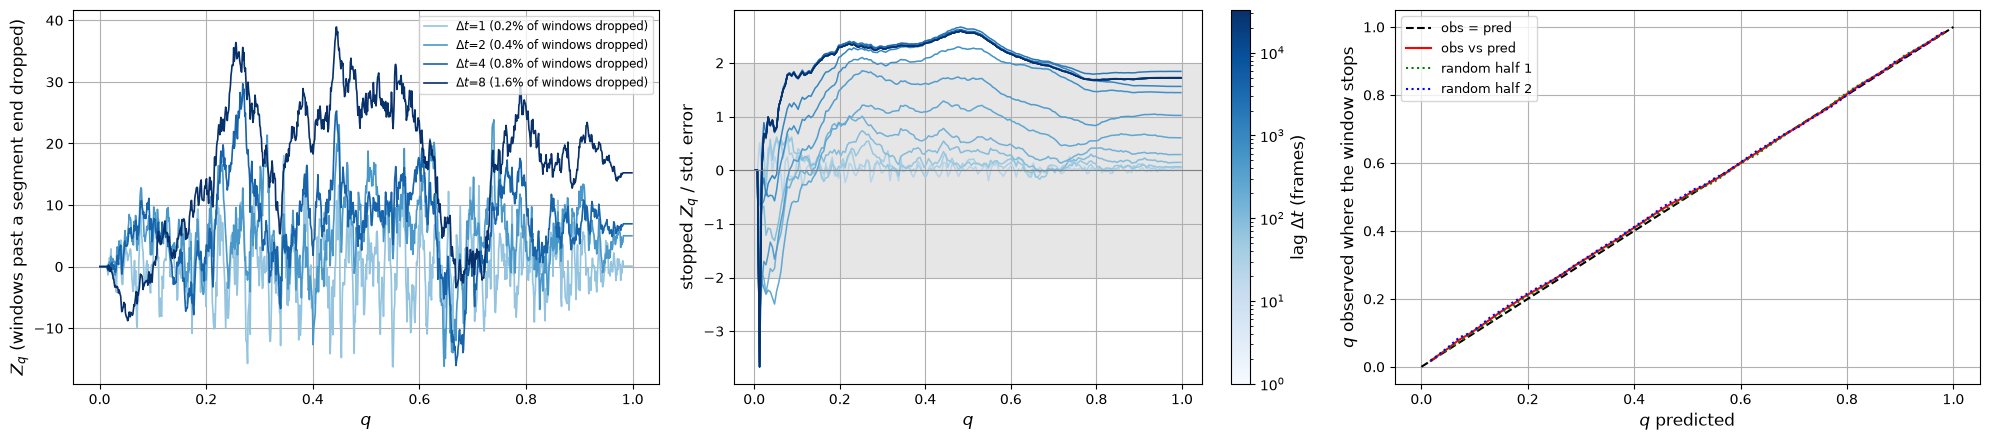

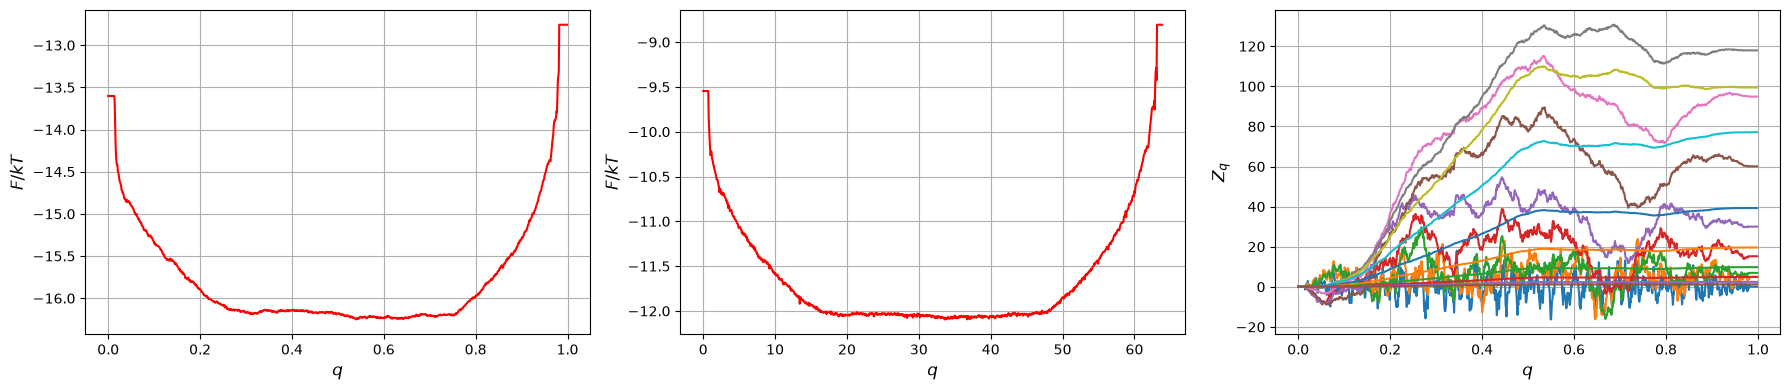

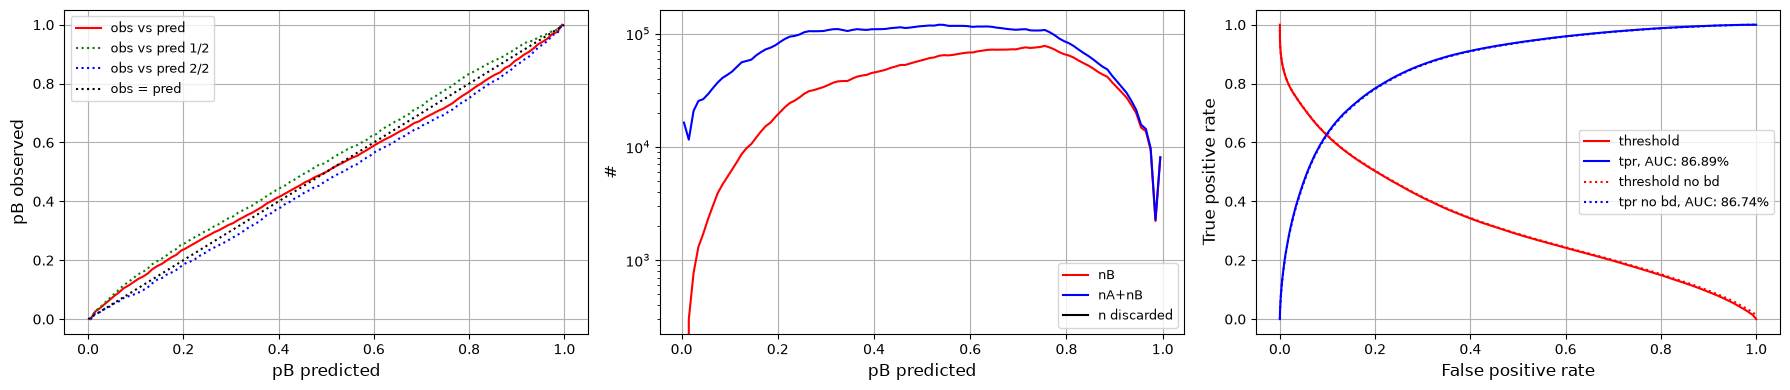

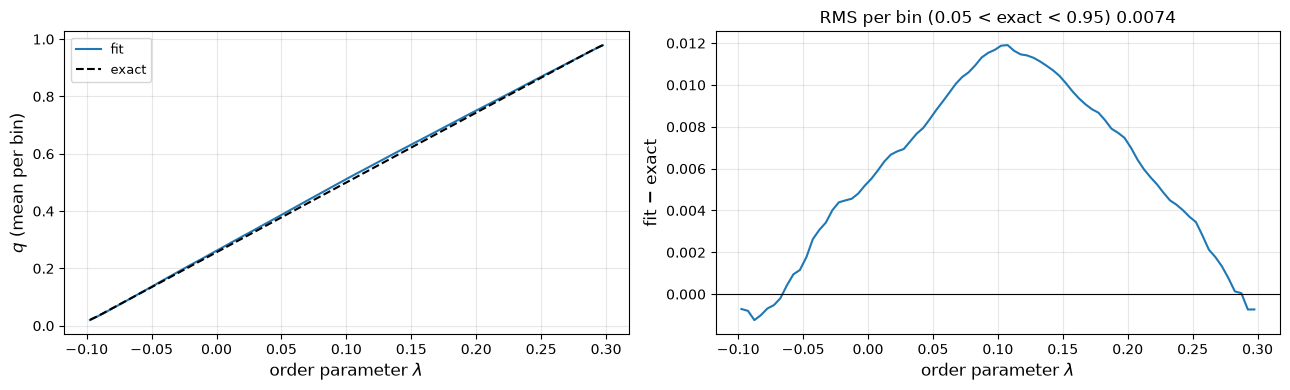

2000 iterations (main, envelope 0.01) | RMS(fit - exact) 0.0081
#=2500, dr2=3918.67, zqs_z=2.67116, sdzqs=45.7361, |dx|=2.34246e-05, time=33.2861
#=3000, dr2=3918.63, zqs_z=2.67058, sdzqs=45.7682, |dx|=3.12274e-05, time=66.0124
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_flat/infretis_staple/flat1d_br/rejections/seed111/it3000 ---


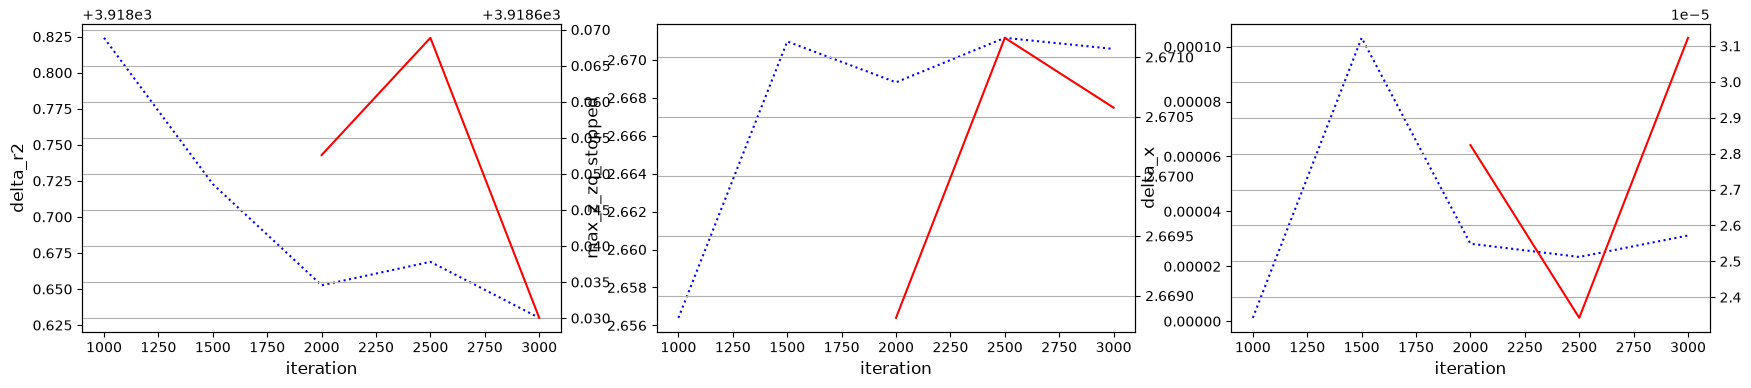

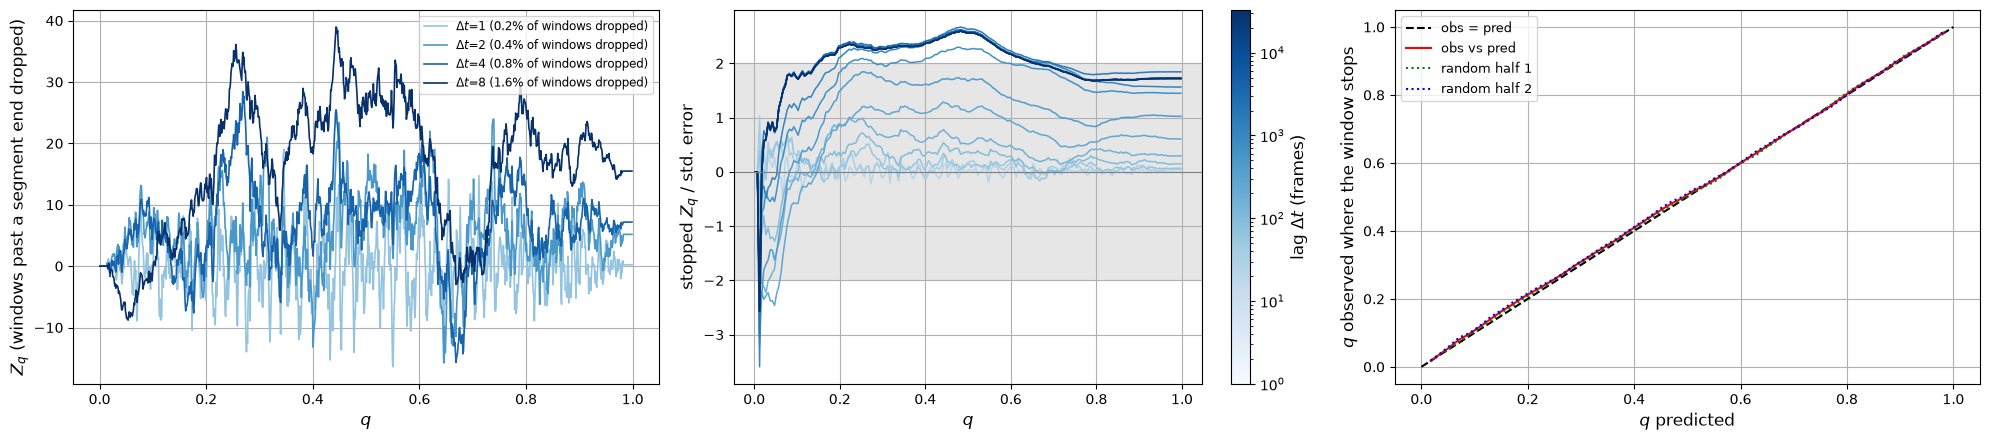

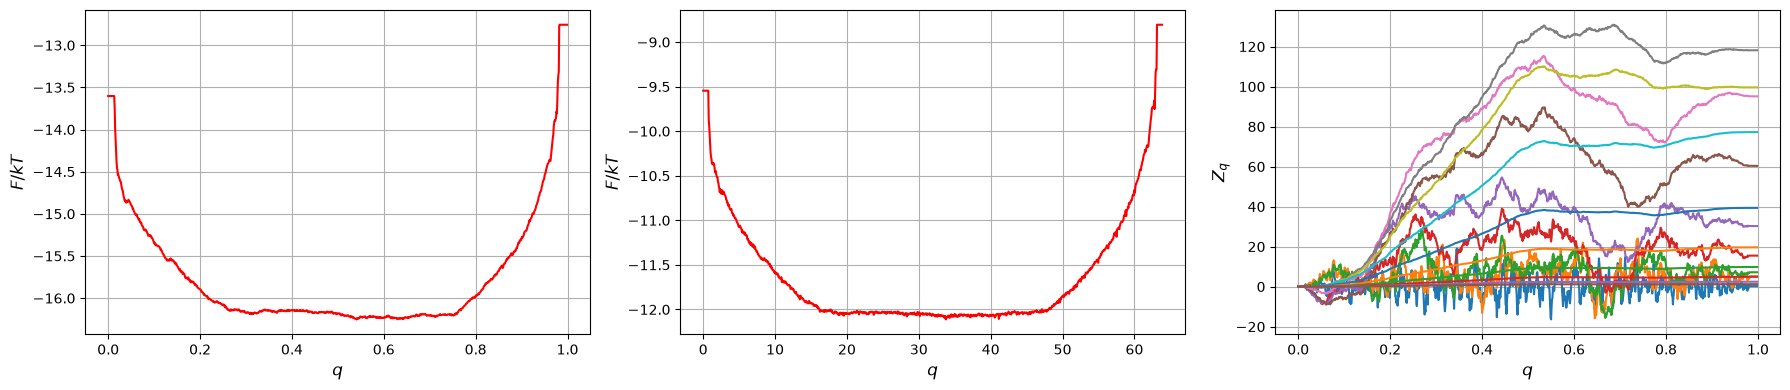

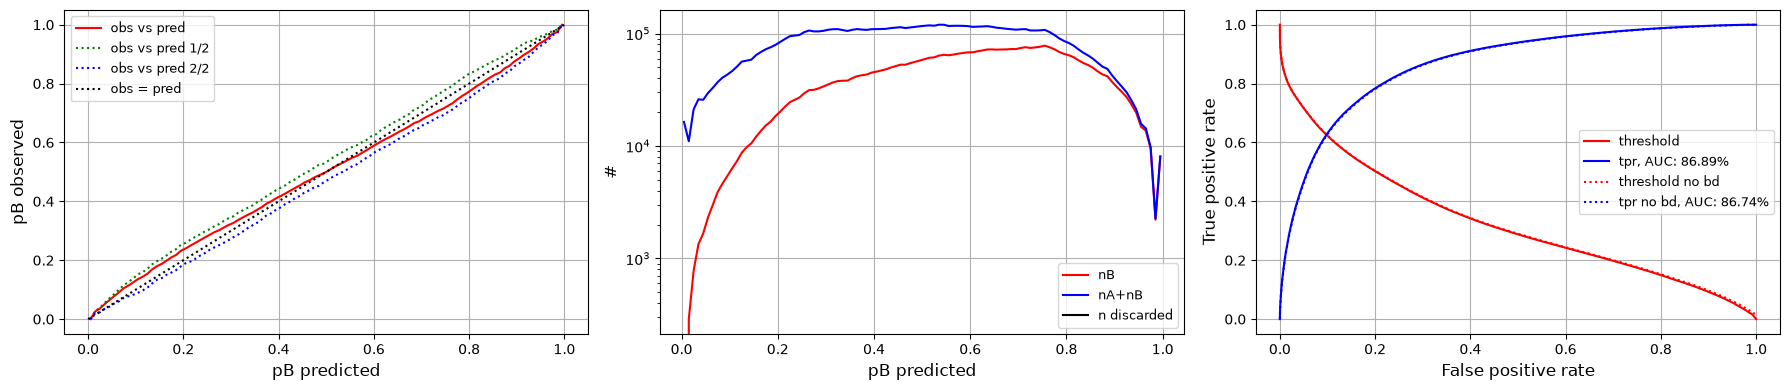

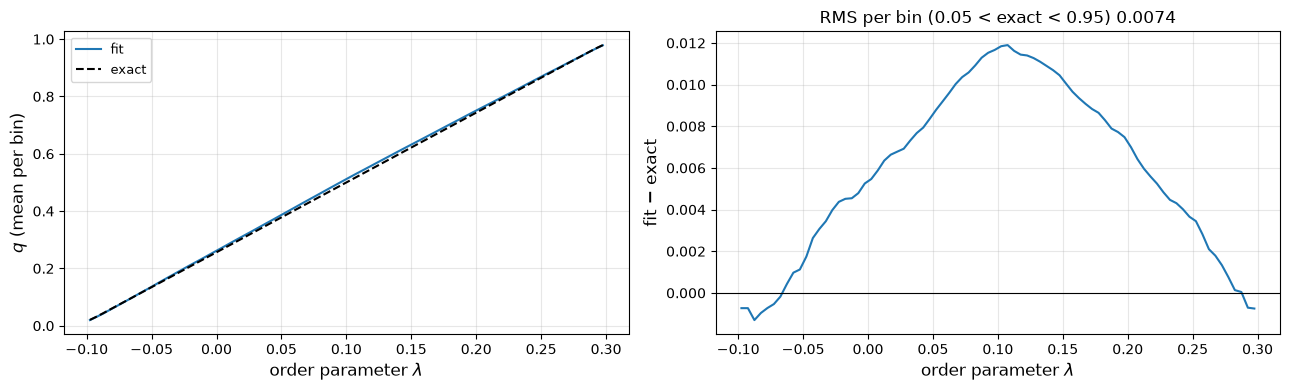

3000 iterations (main, envelope 0.01) | RMS(fit - exact) 0.0081

Training interrupted at iteration 3051; keeping the RC of the last completed update.


Exception ignored on calling weakref callback <function WeakKeyDictionary.__init__.<locals>.remove at 0x7fe60ee74510>:
Traceback (most recent call last):
  File "/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/weakref.py", line 311, in remove
    def remove(k, selfref=ref(self)):
KeyboardInterrupt: 

KeyboardInterrupt



KeyboardInterrupt: 

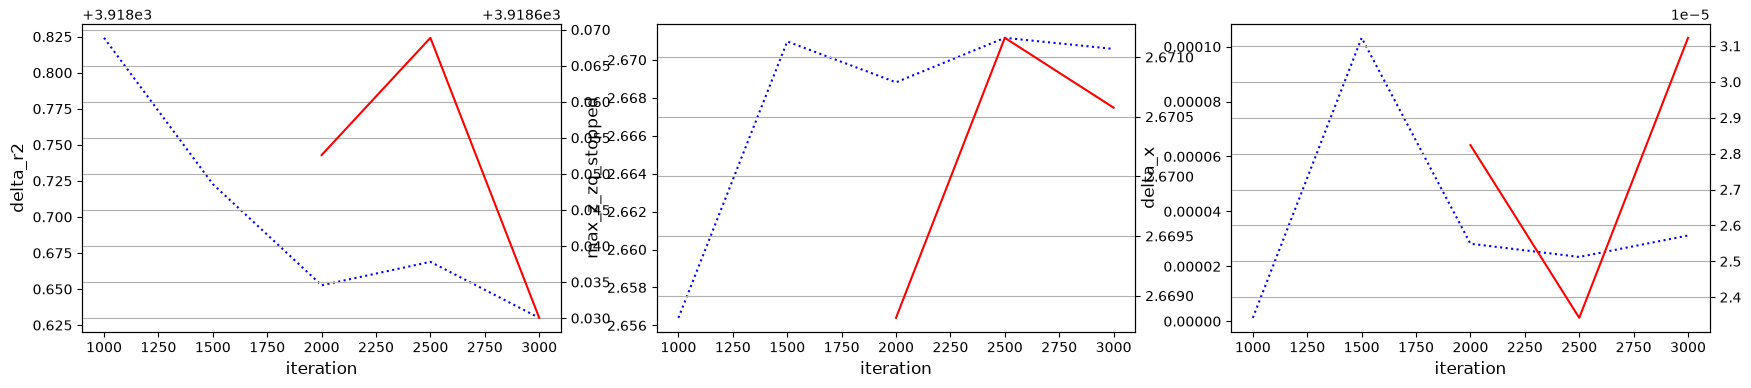

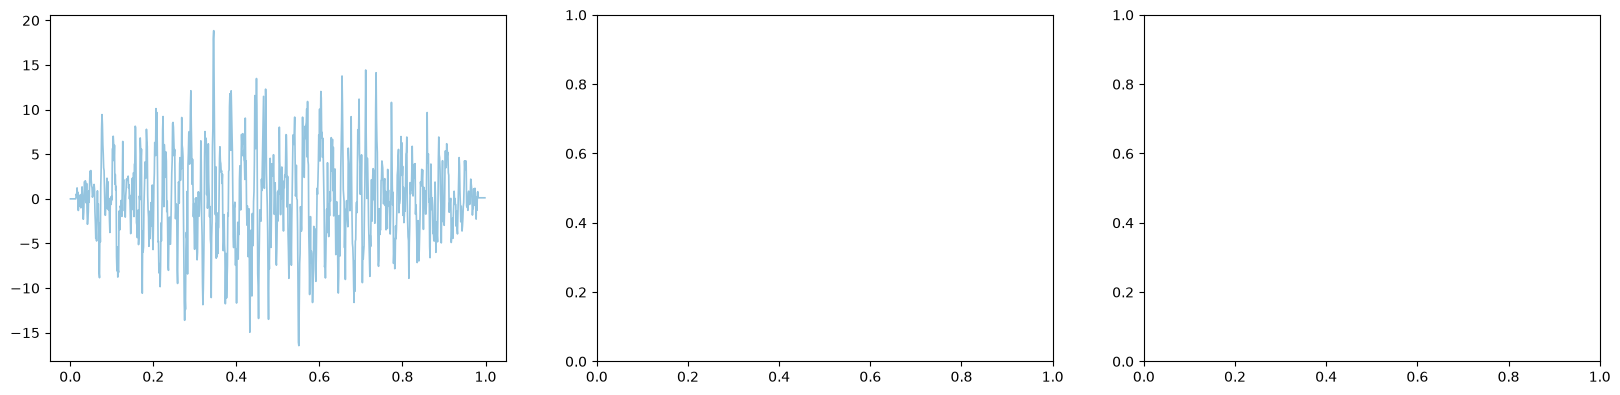

In [71]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
fits = {}                                      # weighting -> final q per seed, exact committor, fit time, zqs_z history
for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seed{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        #del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

[3.33943546e+02 9.70054254e+01 1.59966195e+02 ... 5.18316889e+00
 1.14566714e+02 1.22240369e+10]


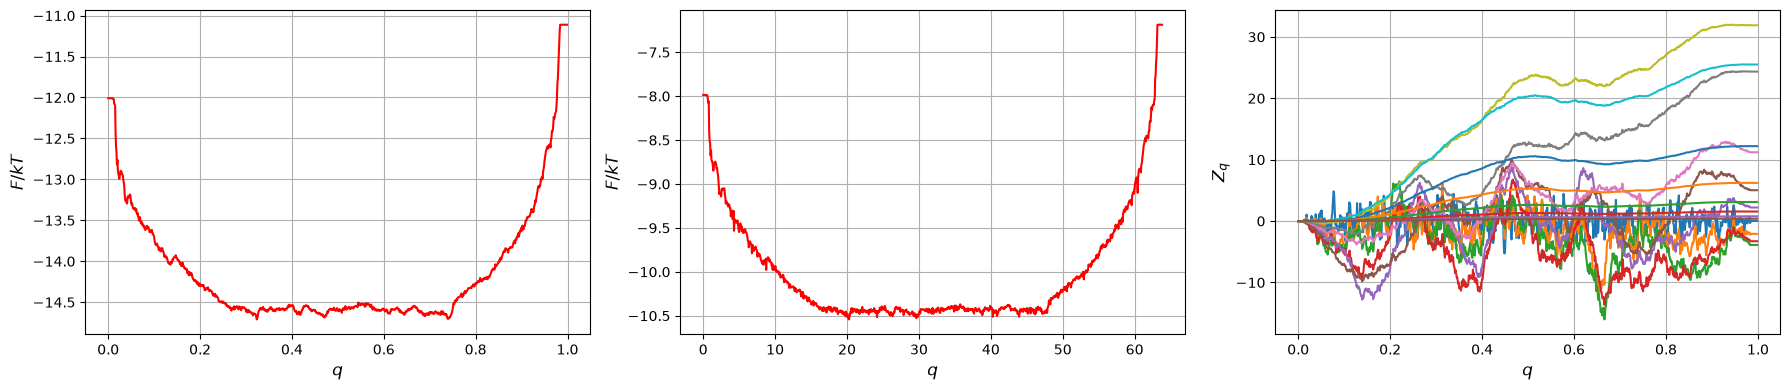

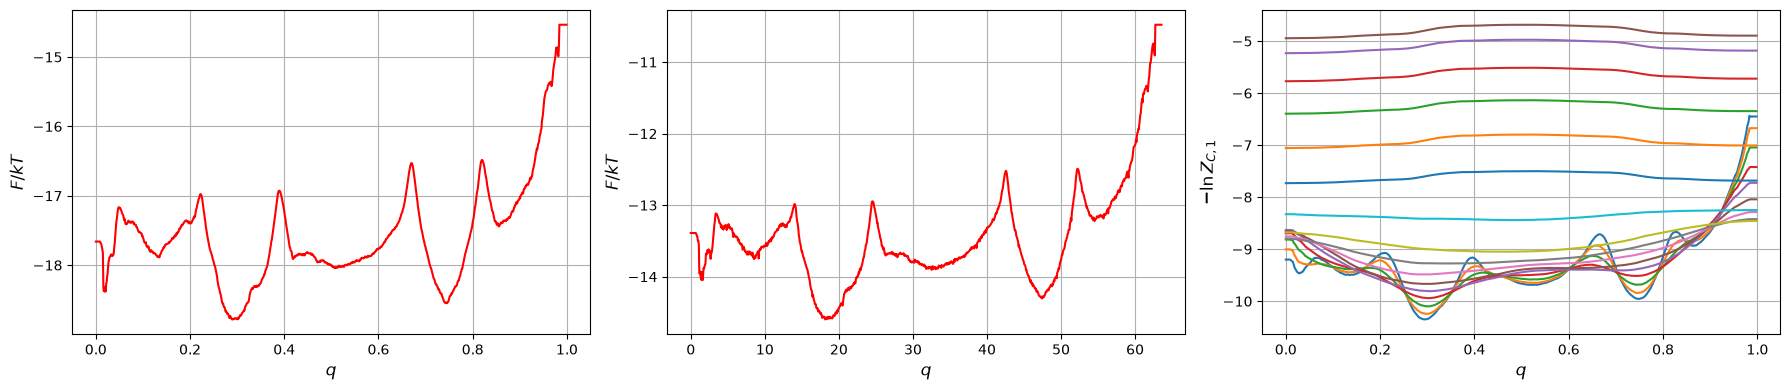

In [12]:
print(q.w_traj)
q.plots_feps()
q.plots_feps(reweight=True)


0.0002


/tmp/ipykernel_973820/2453485671.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


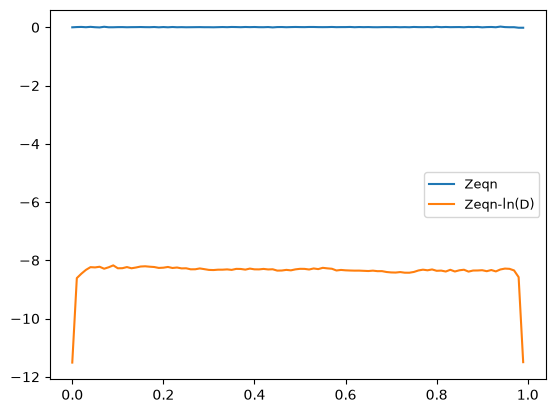

In [64]:
def comp_Zeq1(r_traj, nbins=100, i_traj=None, w_traj=None, start=0, end=-1):
    r_traj = cp.asarray(r_traj)
    r_min = cp.min(r_traj)
    r_max = cp.max(r_traj)
    bin_edges = cp.linspace(r_min, r_max, nbins + 1)
    delta_r = r_traj[1:] - r_traj[:-1]
    It=cp.asarray(i_traj[1:]==i_traj[:-1])
    if w_traj is not None:
        It = It * cp.asarray(w_traj)[:-1]
    delta_r=delta_r*It
    bin_indices_r = cp.searchsorted(bin_edges, r_traj, side='right') - 1
    bin_indices_r = cp.clip(bin_indices_r, 0, len(bin_edges) - 2)
    hist = cp.bincount(bin_indices_r[:-1], minlength=nbins + 1, weights=delta_r)[start:end]
    hist2 = cp.bincount(bin_indices_r[:-1], minlength=nbins + 1, weights=delta_r**2)[start:end]
    n = cp.bincount(bin_indices_r[:-1], minlength=nbins + 1, weights=It)[start:end]
    n+=1
    drift=(hist/n)
    D=(hist2/n-drift**2)/2+1e-5
    Zc1 = cp.cumsum(drift/D)*(bin_edges[1]-bin_edges[0])
    return bin_edges[start:end], Zc1, D

def comp_Zeq(r_traj, nbins=100, i_traj=None, w_traj=None, start=0, end=-1):
    r_traj = cp.asarray(r_traj)  # removed * w_traj here
    r_min = cp.min(r_traj)
    r_max = cp.max(r_traj)
    bin_edges = cp.linspace(r_min, r_max, nbins + 1)
 
    delta_r = r_traj[1:] - r_traj[:-1]
    It = cp.asarray(i_traj[1:] == i_traj[:-1])
    if w_traj is not None:
        It = It * cp.asarray(w_traj)[:-1]  # apply path weights to the step mask instead

    bin_indices_r = cp.searchsorted(bin_edges, r_traj, side='right') - 1
    bin_indices_r = cp.clip(bin_indices_r, 0, len(bin_edges) - 2)
    hist = cp.bincount(bin_indices_r[:-1], minlength=nbins + 1, weights=It * delta_r)[start:end]
    hist2 = cp.bincount(bin_indices_r[:-1], minlength=nbins + 1, weights=It * delta_r**2)[start:end]
    n = cp.bincount(bin_indices_r[:-1], minlength=nbins + 1, weights=It)[start:end]
    n += 1
    drift = (hist / n)
    D = (hist2 / n - drift**2) / 2 + 1e-5
    Zc1 = cp.cumsum(drift / D) * (bin_edges[1] - bin_edges[0])
    return bin_edges[start:end], Zc1, D
print()
bins, zeq, D = comp_Zeq(q.r_traj, i_traj=q.i_traj, w_traj=d.path_weights)
#plt.plot(bins.get(), zeq.get(), label='Zeq')
#plt.plot(bins.get(), (zeq - cp.log(D)).get(), label='Zeq-ln(D)')
#plt.ylim(8,9)
plt.legend()

print(dt)
qn_traj = optimalrcs.plots.transform_q2qn(q.r_traj, i_traj=q.i_traj, t_traj=q.t_traj, w_traj=cp.asarray(d.path_weights), dt_sim=0.002)

binsn, zeqn, Dn = comp_Zeq(q.r_traj, i_traj=q.i_traj, w_traj=d.path_weights)
plt.plot(binsn.get(), zeqn.get(), label='Zeqn')
plt.plot(bins.get(), (-zeqn + cp.log(Dn)).get(), label='Zeqn-ln(D)')
#plt.ylim(8,9)
plt.legend()


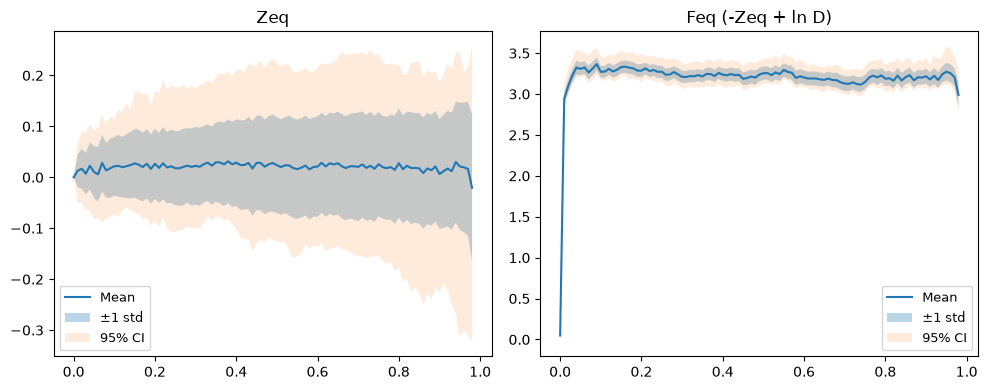

In [51]:
def bootstrap_Zeq(r_traj, i_traj, w_traj, n_boot=50, nbins=100, start=0, end=-1):
    i_gpu = cp.asarray(i_traj)
    _, inv = cp.unique(i_gpu, return_inverse=True)
    n_segs = int(inv.max()) + 1

    bins, _, _ = comp_Zeq(r_traj, nbins=nbins, i_traj=i_traj, w_traj=w_traj, start=start, end=end)
    zeq_boots, feq_boots = [], []

    for _ in range(n_boot):
        # Draw Poisson(1) multiplicity per trajectory piece and broadcast to frames
        seg_mult = cp.random.poisson(1.0, size=n_segs)
        w_boot = cp.asarray(w_traj) * seg_mult[inv]

        _, z_b, D_b = comp_Zeq(r_traj, nbins=nbins, i_traj=i_traj, w_traj=w_boot, start=start, end=end)
        f_b = -(z_b - cp.log(D_b))
        zeq_boots.append(z_b.get())
        feq_boots.append((f_b - cp.nanmin(f_b)).get())

    zeq_boots = np.array(zeq_boots)
    feq_boots = np.array(feq_boots)

    x = bins.get()[:-1]
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for axis, data, title in [(ax[0], zeq_boots[:, :-1], 'Zeq'), (ax[1], feq_boots[:, :-1], 'Feq (-Zeq + ln D)')]:
        mean = np.nanmean(data, axis=0)
        std = np.nanstd(data, axis=0)
        axis.plot(x, mean, label='Mean')
        axis.fill_between(x, mean - std, mean + std, alpha=0.3, label='±1 std')
        axis.fill_between(x, np.nanpercentile(data, 2.5, axis=0), np.nanpercentile(data, 97.5, axis=0), alpha=0.15, label='95% CI')
        axis.set_title(title)
        axis.legend()

    plt.tight_layout()
    plt.show()

bootstrap_Zeq(q.r_traj, q.i_traj, d.path_weights, n_boot=50)

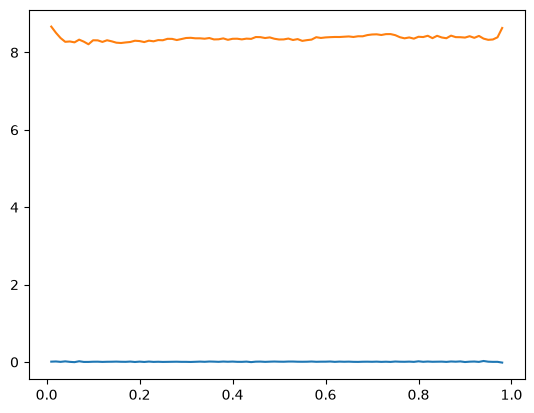

In [30]:
def comp_Zeq(r_traj, i_traj=None, w_traj=None, b_traj=None, nbins=100, start=0, end=-1, min_count=1.0):
    """Zeq(r) = int drift/D dr from the one-step increments of r.
    i_traj: piece of every frame; w_traj: frame weight (path_weights); b_traj: True in A/B.
    A step is used if it stays in its piece and starts outside A/B (a step into A/B counts).
    Bins with fewer than min_count weighted steps give nan."""
    r = cp.asarray(r_traj)
    edges = cp.linspace(r.min(), r.max(), nbins + 1)
    dr = r[1:] - r[:-1]
    ok = cp.ones(len(dr), bool)
    if i_traj is not None:
        i = cp.asarray(i_traj); ok &= i[1:] == i[:-1]
    if b_traj is not None:
        ok &= ~cp.asarray(b_traj, bool)[:-1]
    w = cp.ones(len(dr)) if w_traj is None else cp.asarray(w_traj, dtype=float)[:-1]
    w = w * ok
    dr = cp.where(ok, dr, 0.0)
    b = cp.clip(cp.searchsorted(edges, r, side='right') - 1, 0, nbins - 1)[:-1]
    n  = cp.bincount(b, w, nbins)
    s1 = cp.bincount(b, w * dr, nbins)
    s2 = cp.bincount(b, w * dr ** 2, nbins)
    m = n >= min_count
    nn = cp.where(m, n, 1.0)
    drift = s1 / nn
    D = cp.where(m, (s2 / nn - drift ** 2) / 2, cp.nan)
    zeq = cp.where(m, cp.cumsum(cp.where(m, drift / D, 0.0)) * (edges[1] - edges[0]), cp.nan)
    return edges[start:end], zeq[start:end], D[start:end], n[start:end]

# staple data:
b_all = d.boundary0 | d.boundary1
bins, zeq, D, n = comp_Zeq(q.r_traj, q.i_traj, d.path_weights, b_all, min_count=50)
plt.plot(bins.get()[:-1], zeq.get())   # one value per bin: use the left edges, dro the last point.
plt.plot(bins.get()[:-1], (zeq-cp.log(D)).get())
#plt.ylim(-0.1, 1)

## 7. Results

**Table:** per weighting and seed, the data size, the final and lowest `zqs_z` of the run (its own data; about 2 or less is consistent), and with the exact committor the path-weighted RMS of fit − exact over the frames with 0.05 < q_exact < 0.95 and over the bins in that range.

**Committor along λ:** the path-weighted mean q per λ bin of every fit, the exact committor averaged the same way (dashed), and fit − exact.

,,paths,pieces,frames,zqs_z_final,zqs_z_min,fit_minutes,rms_frames,rms_bins_lambda
weighting,seed,,,,,,,,
rejections,11,14909,38956,8257866,2.6693,2.6564,3.3506,0.0082,0.0074


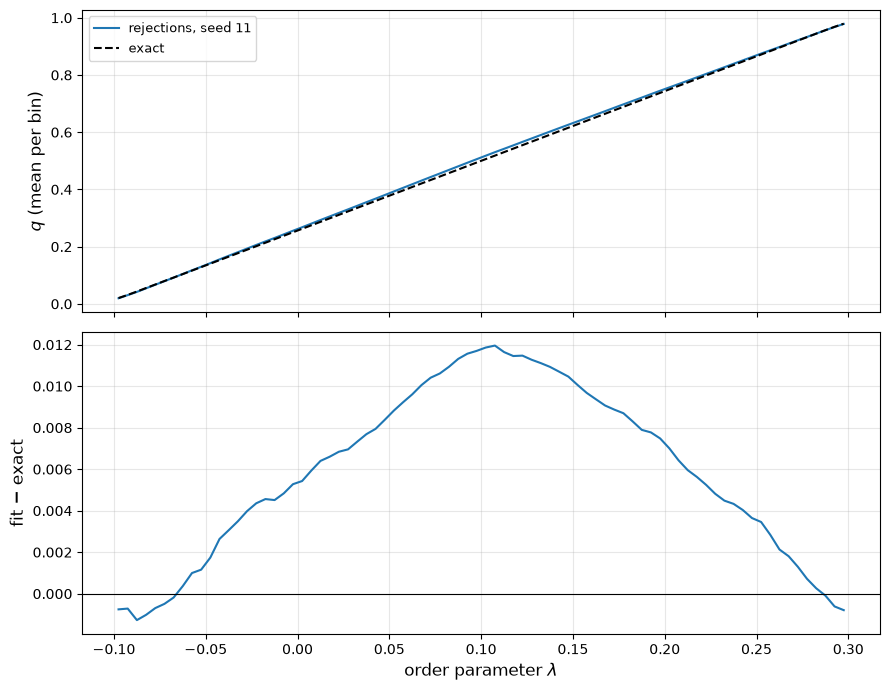

In [29]:
rows, profiles = [], {}
for name, fit in fits.items():
    d = datas[name]
    fr = ~(d.boundary0 | d.boundary1)
    edges = edges_for(d)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    qe = fit['q_exact']
    for s, r in fit['r'].items():
        row = dict(weighting=name, seed=s, paths=len(np.unique(d.group_traj)), pieces=int(d.i_traj.max() + 1),
                   frames=len(r), zqs_z_final=fit['zqs_z'][-1], zqs_z_min=fit['zqs_z'][1:].min(),
                   fit_minutes=fit['t_fit'] / 60 / len(fit['r']))
        profiles[(name, s)] = bm(d.path_weights * r) / w_mean
        if qe is not None:
            t = fr & (qe > 0.05) & (qe < 0.95)
            row['rms_frames'] = np.sqrt(np.sum(d.path_weights[t] * (r[t] - qe[t]) ** 2) / np.sum(d.path_weights[t]))
            pe = bm(d.path_weights * qe) / w_mean
            tb = (pe > 0.05) & (pe < 0.95)
            row['rms_bins_lambda'] = np.sqrt(np.nanmean((profiles[(name, s)] - pe)[tb] ** 2))
            profiles[('exact', name)] = pe
        rows.append(row)
summary = pd.DataFrame(rows).set_index(['weighting', 'seed'])
os.makedirs(OUT, exist_ok=True)
summary.to_csv(f'{OUT}/summary.csv')
display(summary.round(4))

edges = edges_for(data)
mid = (edges[0][1:] + edges[0][:-1]) / 2
has_exact = any(k[0] == 'exact' for k in profiles)
fig, axes = plt.subplots(2 if has_exact else 1, 1, figsize=(9, 7 if has_exact else 4), sharex=True, squeeze=False)
for (name, s), P in profiles.items():
    if name == 'exact':
        continue
    axes[0, 0].plot(mid, P, label=f'{name}, seed {s}')
    if has_exact:
        axes[1, 0].plot(mid, P - profiles[('exact', name)], label=f'{name}, seed {s}')
if has_exact:
    axes[0, 0].plot(mid, profiles[('exact', next(iter(fits)))], 'k--', label='exact')
    axes[1, 0].axhline(0, color='k', lw=0.8)
    axes[1, 0].set(ylabel='fit $-$ exact')
    axes[1, 0].grid(alpha=0.3)
axes[0, 0].set(ylabel='$q$ (mean per bin)')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)
axes[-1, 0].set(xlabel=XLABEL)
fig.tight_layout()
fig.savefig(f'{OUT}/profiles.png', dpi=110)
plt.show()

## 8. Save

Every fit's q per frame with its frames, in the format of `load_tis_data_cupy.py`'s `committor.npz` (`r`, `lam`, `X_all`, `i_traj`, `t_traj`, `group_traj`, `path_weights`, `boundary0`, `boundary1`), as `<OUT>/<weighting>/seed<s>/committor.npz`. (`run_seeds` also saved each final q alone as `q_traj.npy`.)

In [30]:
for name, fit in fits.items():
    d = datas[name]
    for s, r in fit['r'].items():
        path = f'{OUT}/{name}/seed{s}/committor.npz'
        np.savez(path, r=r, lam=d.lam, X_all=d.X_all, i_traj=d.i_traj, t_traj=d.t_traj, group_traj=d.group_traj,
                 path_weights=d.path_weights, boundary0=d.boundary0, boundary1=d.boundary1,
                 weighting=name, tis_dir=TIS_DIR)
        print('saved', path)

saved /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_flat/infretis_staple/flat1d_br/rejections/seed11/committor.npz
